## Image Restoration

In [7]:
import numpy as np
import matplotlib.pyplot as plt

In [8]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
f = plt.imread(imgpath+'/test-pattern.tif')
f.shape

(604, 604)

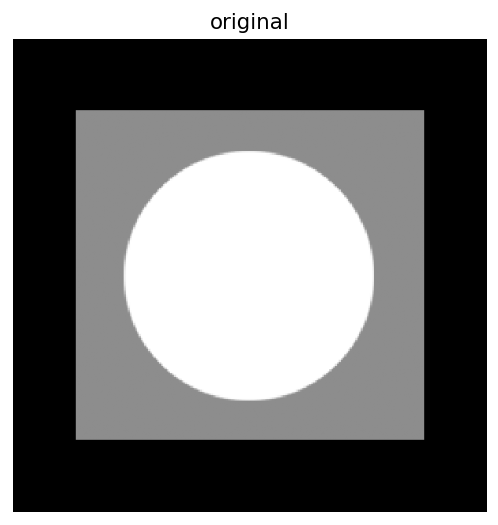

In [10]:
plt.figure(dpi=128)
plt.imshow(f, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('original')
plt.show()

### Gaussian Noise

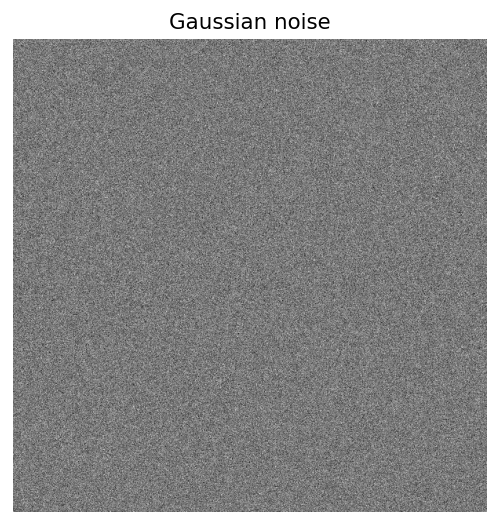

In [11]:
n_gauss = np.random.normal(0,32,f.shape)
plt.figure(dpi=128)
plt.imshow(n_gauss, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('Gaussian noise')
plt.show()

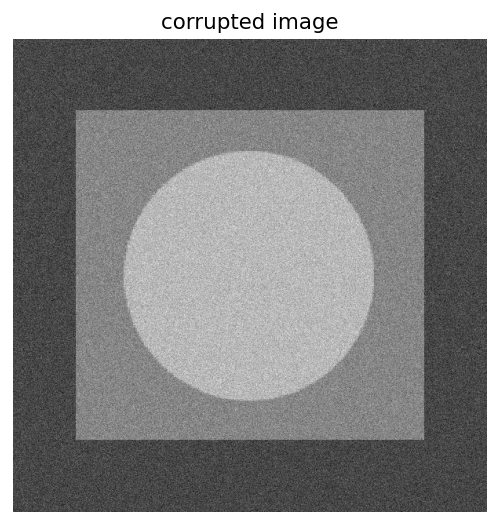

In [12]:
f_n = f + n_gauss
plt.figure(dpi=128)
plt.imshow(f_n,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('corrupted image')
plt.show()

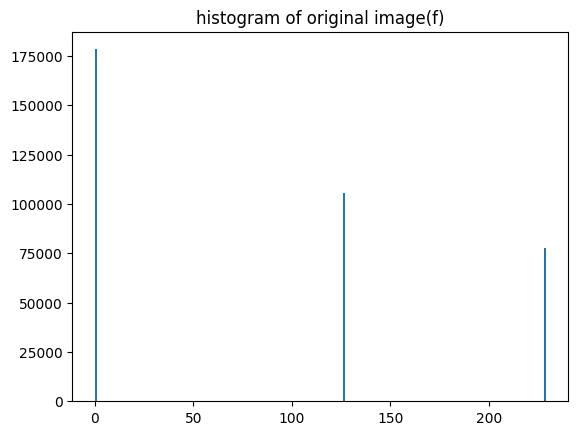

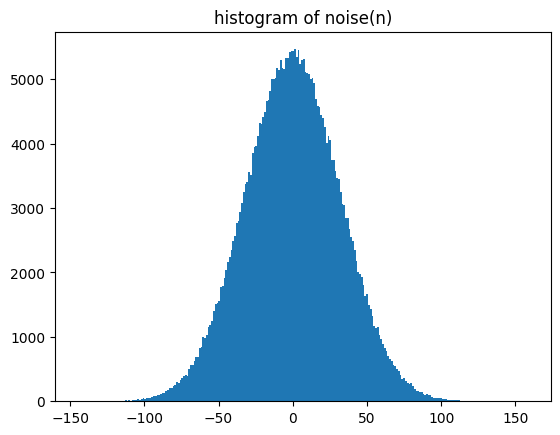

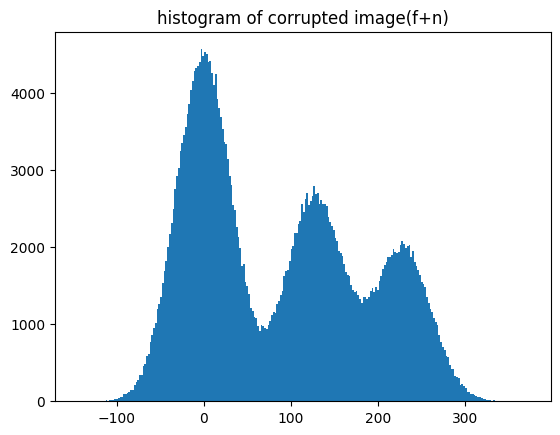

In [13]:
plt.hist(f.ravel(),256)
plt.title('histogram of original image(f)')
plt.show()
plt.hist(n_gauss.ravel(),256)
plt.title('histogram of noise(n)')
plt.show()
plt.hist(f_n.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

### Salt and Pepper Noise

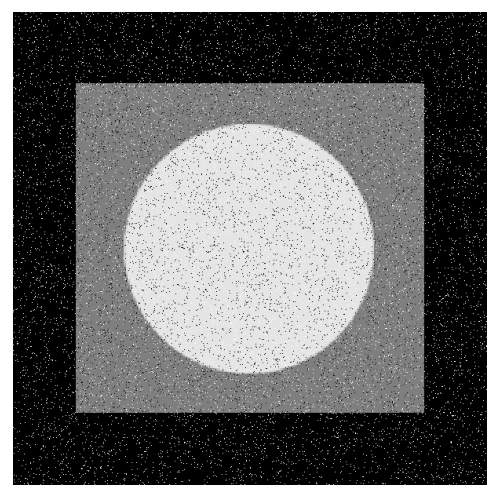

In [14]:
sp = np.random.randint(0,100,np.shape(f))
f_sp = f.copy()
f_sp[sp<3] = 0
f_sp[sp>96] = 255

plt.figure(dpi=128)
plt.imshow(f_sp,cmap='gray',aspect='equal')
plt.axis('off')
plt.show()

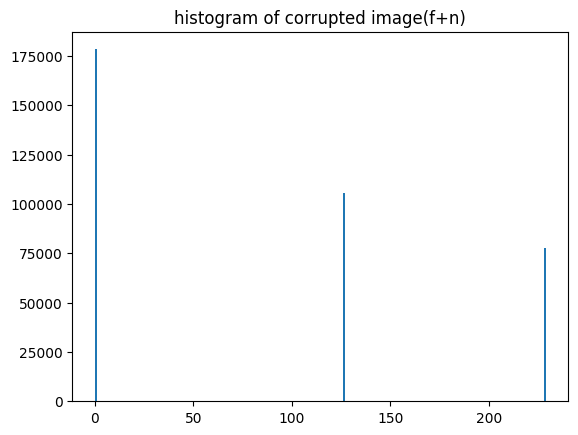

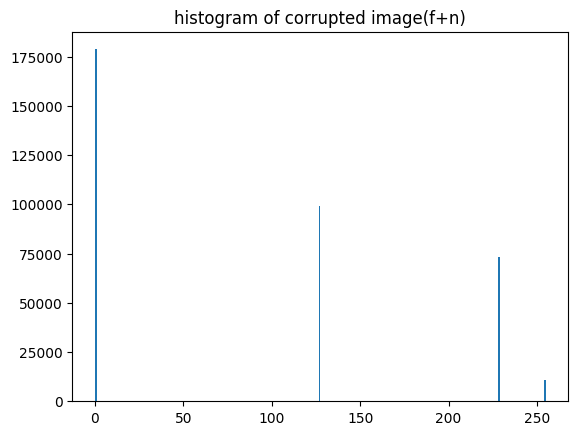

In [15]:
plt.hist(f.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

plt.hist(f_sp.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

### Mean vs Median Filtering

In [16]:
SS = 7 # kernel size (square kernel)
ss = int((SS-1)/2)
r_median = np.zeros(np.shape(f_sp))
r_mean = np.zeros(np.shape(f_sp))

In [17]:
for x in range(ss,np.size(f_sp,0)-ss):
  for y in range(ss,np.size(f_sp,1)-ss):
    Sxy = f_sp[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    r_median[x,y] = np.median(Sxy)

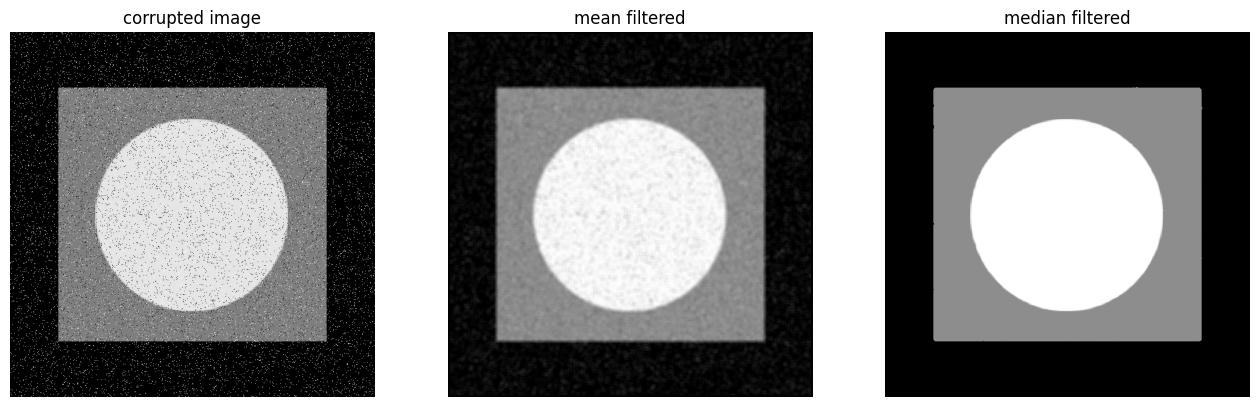

In [18]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f_sp,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('mean filtered')
plt.subplot(133)
plt.imshow(r_median,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('median filtered')
plt.show()

## Adaptive Local Noise Reduction

In [19]:
# Adaptive local noise reduction
f = f_n

std_eta = 16
SS = 5

ss = int((SS-1)/2)
r_amean = np.zeros(np.shape(f))
for x in range(ss,np.size(f,0)-ss):
  for y in range(ss,np.size(f,1)-ss):
    Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    std_Sxy = np.std(Sxy)
    r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))

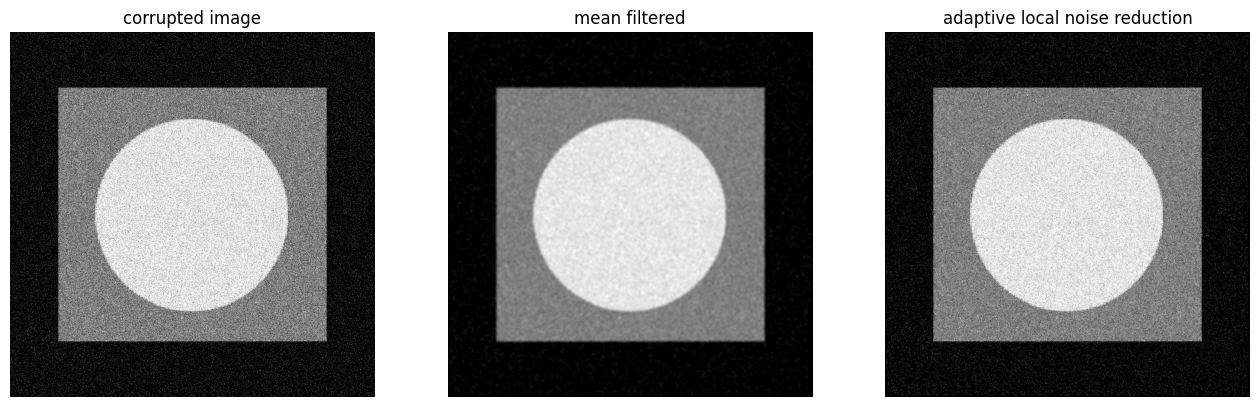

In [20]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f_n,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('mean filtered')
plt.subplot(133)
plt.imshow(r_amean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction')
plt.show()

## Adaptive Median Filtering

In [21]:
# Adaptive Median Filtering
#f = f_sp
f = plt.imread(imgpath+'/circuitboard-saltandpep.tif')
SS_vals = np.array([3, 5, 7])
r_amedian = np.zeros(np.shape(f))
r_median = np.zeros(np.shape(f))
r_case = np.zeros(np.shape(f))

ss_max = int((np.max(SS_vals)-1)/2)
for x in range(ss_max,np.size(f,0)-ss_max):
  for y in range(ss_max,np.size(f,1)-ss_max):
    flag_go = 1
    cnt = 0
    z_xy = f[x,y]
    for SS in SS_vals:
      ss = int((SS-1)/2)
      Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
      z_med = np.median(Sxy)
      z_min = np.min(Sxy)
      z_max = np.max(Sxy)

      if cnt==0:
        r_median[x,y] = z_med

      if z_min<z_med and z_med<z_max:
        if z_min<z_xy and z_xy<z_max:
          r_amedian[x,y] = z_xy
          flag_go = 0
        else:
          r_amedian[x,y] = z_med
          flag_go = 0
      else:
        if SS == np.max(SS_vals):
          r_amedian[x,y] = z_med
          flag_go = 0

      if flag_go==0:
        r_case[x,y] = cnt
        break
      cnt = cnt+1

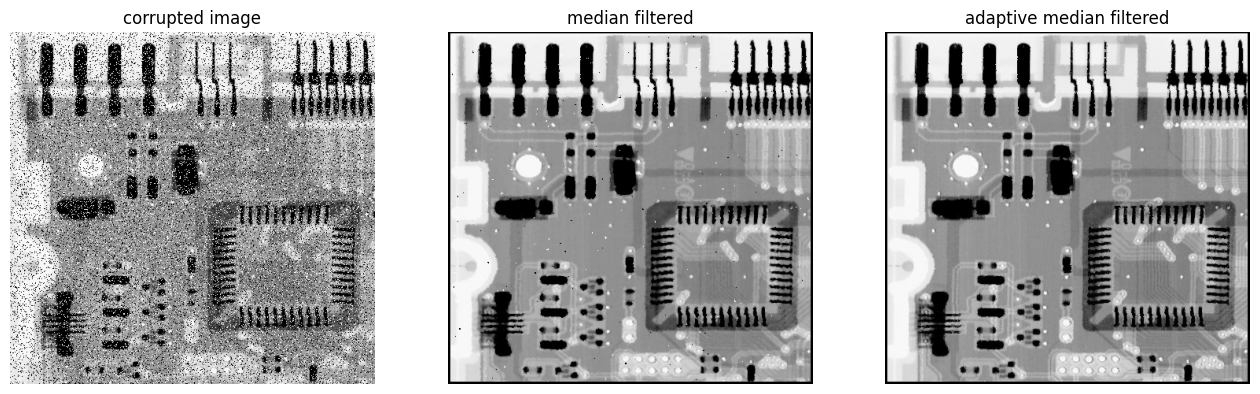

In [22]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_median,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('median filtered')
plt.subplot(133)
plt.imshow(r_amedian,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive median filtered')
plt.show()

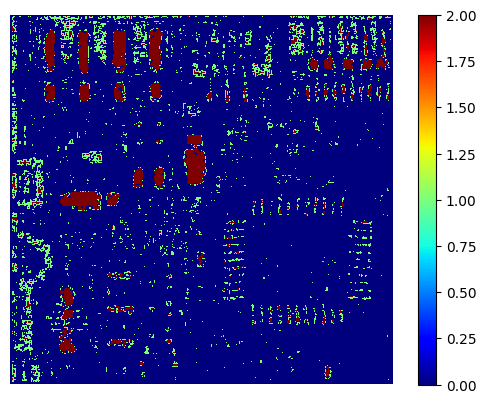

In [23]:
plt.imshow(r_case,cmap='jet',interpolation='nearest')
plt.axis('off')
plt.colorbar()
plt.show()

## Exercise
- 두 개의 noisy image를 각각 f1, f2로 불러오고 적절한 restoration(denoising)을 수행해보자.

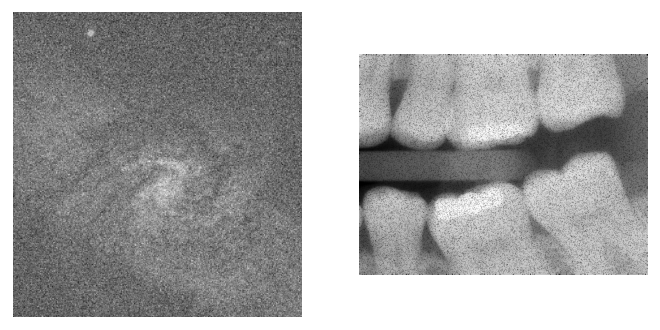

In [3]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()

- 복원코드를 직접 작성해보기.

In [4]:
# 은하 영상은 가우시안 잡음으로 보고 적응형 국소 잡음 감소 필터를 적용했습니다.
# 커널 크기는 3x3, 5x5, 7x7로 바꿔가며 결과를 비교했습니다.
# 7x7에서는 은하의 세부 구조가 너무 뭉개졌고,
# 3x3이 잡음을 줄이면서 원래 형태도 가장 적당하게 유지하는 것 같아서 선택했습니다.
g = f1.astype(np.float64)
h, w = g.shape

# 잡음 분산을 구하기 위해 밝기가 비교적 일정한 배경 영역을 사용했습니다.
# 왼쪽 위에서 별이나 은하가 없는 배경이라고 가정한 부분을 선택했습니다.
noise_region = g[int(h*0.04):int(h*0.20),
                 int(w*0.04):int(w*0.18)]
var_eta = np.var(noise_region)

# 가장자리에도 필터를 적용할 수 있도록 주변 값을 반사하는 방식으로 패딩했습니다.
g_pad = np.pad(g, 1, mode='reflect')
f1_r = np.zeros(g.shape)

for x in range(h):
    for y in range(w):
        # 현재 픽셀 주변의 3x3 영역을 가져와 평균과 분산을 계산했습니다.
        Sxy = g_pad[x:x+3, y:y+3]
        mean_Sxy = np.mean(Sxy)
        var_Sxy = np.var(Sxy)

        # 주변 분산이 0이면 밝기가 모두 같으므로 평균값을 넣었습니다.
        # 이 경우를 따로 처리해서 0으로 나누는 문제도 방지했습니다.
        if var_Sxy == 0:
            f1_r[x, y] = mean_Sxy
        else:
            # 강의자료의 가정에 맞춰 분산의 비율이 1을 넘지 않도록 제한했습니다.
            # 주변 분산이 크면 원래 픽셀값을 더 유지하고,
            # 잡음 분산과 비슷하면 주변 평균에 가까워지도록 보정했습니다.
            ratio = min(var_eta / var_Sxy, 1.0)
            f1_r[x, y] = g[x, y] - ratio * (g[x, y] - mean_Sxy)


# 치아 영상은 검은 점 형태의 pepper 잡음을 줄이기 위해 최댓값 필터를 적용했습니다.
# 주변의 밝은 값으로 검은 점을 채우지만 밝은 영역이 넓어질 수도 있어서,
# 커널 크기는 3x3으로 설정했습니다.
g = f2.astype(np.float64)
h, w = g.shape

g_pad = np.pad(g, 1, mode='reflect')
f2_r = np.zeros(g.shape)

for x in range(h):
    for y in range(w):
        # 주변 9개 픽셀 중 가장 큰 밝기값을 복원값으로 넣었습니다.
        Sxy = g_pad[x:x+3, y:y+3]
        f2_r[x, y] = np.max(Sxy)

- 복원된 f1, f2를 시각화하기

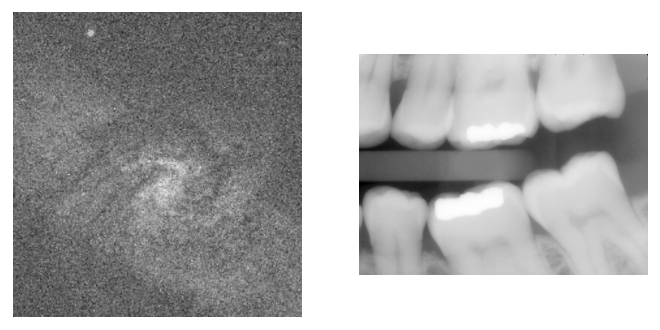

In [5]:
# f1_r: denoised f1
# f2_r: denoised f2
plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1_r,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2_r,cmap='gray')
plt.axis('off')
plt.show()

- 복원된 f1, f2를 그림파일로 저장하기

In [6]:
plt.imsave('denoised-galaxy-pair.png',f1_r,cmap='gray')
plt.imsave('denoised-dentalXray.png',f2_r,cmap='gray')